# Figs. 4, 5 and 6: Distribution functions with and without truncation

This notebook makes Figures 4, 5 and 6 of the paper.

* **Fig. 4** (`DF_Untruncation_DFs.pdf`): top, the anisotropy $\beta_\sigma(R)$ of each family in closed form; bottom, the
  untruncated distribution function $F(\mathcal{K})$ of the NFW density with that anisotropy (`pp.compute_df`).
* **Fig. 5** (`DF_Truncation_DFs_I.pdf`): Method I, each member truncated at its own $\mathcal{K}_{\rm t}$ (`pp.truncate` of the
  untruncated DF with `pp.Truncation(k_t=...)`, which is what `pp.solve` does); top, $\hat F(\hat{\mathcal{K}})$ with
  $\hat{\mathcal{K}} = \mathcal{K} - \mathcal{K}_{\rm t}$; bottom, the truncated density $\hat\varrho(R)$.
* **Fig. 6** (`DF_Truncation_DFs_II.pdf`): Method II, the isotropic NFW truncated at $\mathcal{K}_{\rm t} = 0.1651$ (the Method I model) and
  each member a model with its anisotropy on that model's truncated density (`pp.solve(pp.Component(truncated.profile, ...))`); top,
  $\hat F(\hat{\mathcal{K}})$; bottom, $\sigma_{\rm 3D}/\sigma_0$ from `pp.sigma_r` and `pp.sigma_t`,
  $\sigma_0 = (\ln 11 - 10/11)^{1/2}$.

The figures are drawn in the published style: the page, the frames and the text positions of the original Mathematica exports
(`data/fig04_05_06/layout_fig04.json`, `_fig05`, `_fig06`), the ticks inward on all four sides at their printed size, the curve
labels at the exports' positions, all text in DejaVu Sans (`scripts/mma_port.py`, `scripts/dejavu_labels.py`). The dashed vertical lines at
the truncation energies are those of the published figures. Every curve is computed here by the package's public calls; nothing is read
from stored model data. A model the package refuses is printed with its reason and left out.

Per-call accuracy messages are quieted; the summary after each figure's models lists every model's tier.

In [1]:
import math
import os

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"  # before any JAX import: no C++ log lines from XLA
import logging

# matplotlib's Computer Modern fonts carry very old timestamps, which fontTools reports while the PDFs embed them
logging.getLogger("fontTools").setLevel(logging.ERROR)
import sys

import numpy as np

import pianistpy as pp

sys.path.insert(0, "scripts")
import mma_port as mp  # noqa: E402

DATA = "data/fig04_05_06"
NFW = pp.DoublePowerLaw.nfw()
C = mp.C                                     # the colors of the published figures (exact RGB of the exports)
FRAME = mp.FRAME                             # 224.46 pt, the frame side of the exports
PRINTED = {0.04: 4.08, 0.02: 2.45, 0.01: 1.225}   # the FrameTicks sizes (fraction of the frame) -> pt as printed


def printed_scale(W):
    """The printed scale of a page W pt wide placed at 0.99 of the text width (506.1 pt); frame and tick lines 1.02 pt as printed."""
    s = 0.99 * 506.1 / W
    mp.LW_FRAME = 1.02 / s
    return s


def tick(ax, side, vals, size, s):
    """inward ticks of a FrameTicks entry on one side, drawn at their printed length"""
    mp.ticks(ax, side, vals, PRINTED[size] / s / FRAME)


def logF_frame(page, col, row, s):
    """a log10 F frame of the three figures: K (or K^) in [0, 1], F in [10^-7.8, 10^7.8]"""
    ax = page.frame(col, row, "linear", (0.0, 1.0), "log", (10 ** -7.8, 10 ** 7.8))
    dec = [10.0 ** x for x in mp.arange(-10, 10, 1.0)]
    tick(ax, "left", dec, 0.02, s); tick(ax, "left", [10.0 ** x for x in range(-10, 9, 2)], 0.04, s)
    tick(ax, "right", dec, 0.02, s); tick(ax, "right", [10.0 ** x for x in range(-10, 11, 2)], 0.04, s)
    tick(ax, "bottom", mp.arange(0, 1, 0.05), 0.02, s); tick(ax, "bottom", [0.2, 0.4, 0.6, 0.8, 1.0], 0.04, s)
    tick(ax, "top", mp.arange(0, 1, 0.05), 0.02, s); tick(ax, "top", mp.arange(0, 1, 0.2), 0.04, s)
    return ax


def shifted(sp, dx, dy):
    """a text span moved by (dx, dy) pt (x right, y down)"""
    if not (dx or dy):
        return sp
    out = dict(sp, origin=[sp["origin"][0] + dx, sp["origin"][1] + dy])
    if "chars" in sp:
        out["chars"] = [[c, [o[0] + dx, o[1] + dy]] for c, o in sp["chars"]]
    return out


# every model of the three figures: tag -> (family, R_a, beta_c)
FAMILY = {"iso": ("iso", None, 0.0), "b+0.50": ("const", None, 0.5), "b-0.50": ("const", None, -0.5)}
for ra in (1, 10, 100):
    FAMILY[f"OMI_Ra{ra}"] = ("OMI", ra, 0.0)
    FAMILY[f"OMII_Ra{ra}"] = ("OMII", ra, 0.0)
    for bc in ("+0.25", "-0.25"):
        FAMILY[f"COMI_b{bc}_Ra{ra}"] = ("COMI", ra, float(bc))
        FAMILY[f"COMII_b{bc}_Ra{ra}"] = ("COMII", ra, float(bc))

FIG4 = list(FAMILY)                          # Fig. 4: all 21, untruncated
FIG5_KT = {                                  # Fig. 5: Method I, each member at its own K_t
    "iso": 0.16497796163238299, "b+0.50": 0.19986231811501387, "b-0.50": 0.1603510056974926,
    "OMI_Ra10": 0.13454, "OMI_Ra100": 0.1643, "OMII_Ra10": 0.225, "OMII_Ra100": 0.165,
    "COMI_b+0.25_Ra100": 0.172, "COMI_b-0.25_Ra10": 0.135, "COMI_b-0.25_Ra100": 0.16125,
    "COMII_b+0.25_Ra10": 0.262, "COMII_b+0.25_Ra100": 0.1742, "COMII_b-0.25_Ra10": 0.217, "COMII_b-0.25_Ra100": 0.162}
FIG6_KT = 0.1651                             # Fig. 6: the Method I model's K_t (isotropic)
FIG6 = ["b+0.50", "b-0.50", "OMI_Ra1", "OMI_Ra10", "OMI_Ra100", "OMII_Ra100", "COMI_b+0.25_Ra100", "COMI_b-0.25_Ra1",
        "COMI_b-0.25_Ra10", "COMI_b-0.25_Ra100", "COMII_b+0.25_Ra100", "COMII_b-0.25_Ra100"]


def anisotropy(tag):
    kind, r_a, beta_c = FAMILY[tag]
    if kind == "iso":
        return pp.Anisotropy()
    if kind == "const":
        return pp.Anisotropy(beta_c=beta_c)
    fam = "II" if kind.endswith("II") else "I"
    if kind.startswith("COM"):
        return pp.Anisotropy(beta_c=beta_c, r_a=float(r_a), kind=fam)
    return pp.Anisotropy(r_a=float(r_a), kind=fam)


def made(name, call):
    """The result of a public call, or None with the package's refusal printed."""
    try:
        return call()
    except pp.PianistpyError as e:
        print(f"{name}: refused by the package: {type(e).__name__}: {str(e).splitlines()[0][:300]}")
        return None


def df_table(result):
    """The DF table of a result: K and F (F signed where the inversion makes it negative)."""
    k = np.asarray(result.table.k[0])
    f = 10.0 ** np.asarray(result.table.log_df[0])
    sign = np.asarray(result.table.sign[0]) if np.size(result.table.sign) else np.ones_like(k)
    return k, np.where(sign < 0, -f, f)


def beta_closed(tag, R):
    """beta_sigma(R) of each family in closed form; a Type II family is -1e5 outside R_a, where it is not defined"""
    kind, ra, bc = FAMILY[tag]
    if kind in ("iso", "const"):
        return np.full_like(R, bc)
    q = (ra / R) ** 2
    qq = (ra / np.minimum(R, ra * (1 - 1e-15))) ** 2          # a Type II family evaluated inside R_a only
    return {"OMI": 1 / (1 + q), "COMI": (1 + bc * q) / (1 + q),
            "OMII": np.where(R < ra, 1 / (1 - qq), -1e5), "COMII": np.where(R < ra, (1 - bc * qq) / (1 - qq), -1e5)}[kind]

In [2]:
import logging
import math
import warnings

import pianistpy as pp

# The figures of the paper are made with ver. 1.0.0 of the package; any other installed version stops the notebook here.
PIANISTPY_PIN = "1.0.0"
print(f"pianistpy {pp.__version__}")
if pp.__version__ != PIANISTPY_PIN:
    raise RuntimeError(
        f"These figures are made with pianistpy {PIANISTPY_PIN}; the installed version is {pp.__version__}."
    )

# The package reports each result's accuracy twice per call: a line of the pianistpy log and Python's AccuracyWarning.
# set_verbosity("quiet") hides the log's INFO line of a result in the band "recorded"; the pianistpy logger set to
# ERROR also hides the log's WARNING line of a result in the band "warned"; the filter hides the AccuracyWarning.
# The summary after each figure's models prints every model's tier in place of those per-call messages.
pp.set_verbosity("quiet")
logging.getLogger("pianistpy").setLevel(logging.ERROR)
warnings.filterwarnings("ignore", category=pp.AccuracyWarning)


def tier_line(label, result):
    """One summary line for a result: its label, its report's tier, and the report's worst check with that check's error.

    The worst check is the check of the highest tier level; among checks of one level, the check with the largest error.
    A result whose tier is carried from the Method I model's report, and not from any of the result's own checks, says so.
    """
    if result is None:
        return f"{label:34s} not built: the package's exception is printed above"
    report = result.validation

    def rank(key):
        error = report.checks[key].error
        return (report.checks[key].level, error if not math.isnan(error) else -math.inf)

    worst = max(report.keys, key=rank)
    own_level = report.checks[worst].level
    origin = ", the tier carried from the Method I model's report" if report.parents_level > own_level else ""
    return (f"{label:34s} tier {report.tier:9s} worst check {worst} "
            f"{report.checks[worst].error:.2e}{origin}")


pianistpy 1.0.0


## The models

The untruncated DF of each of the 21 members is computed once (`pp.compute_df`): Fig. 4 draws them, and the Method I models of
Fig. 5 and the Method I model of Fig. 6 are their truncations (`pp.truncate`; `pp.solve(component, truncation)` is `compute_df` followed by
`truncate`). The members of Fig. 6 are new inversions on the Method I model's truncated density.

In [3]:
dfs = {tag: made(f"{tag} (untruncated)", lambda tag=tag: pp.compute_df(pp.Component(NFW, anisotropy(tag)))) for tag in FIG4}
for tag, d in dfs.items():
    if d is not None:
        k, f = df_table(d)
        print(f"{tag:20s} {k.size:6d} rows, K in [{k[0]:.3e}, {k[-1]:.10f}], F < 0 on {int(np.sum(f < 0))} rows")

iso                    9655 rows, K in [2.007e-10, 0.9999999990], F < 0 on 0 rows
b+0.50                 9656 rows, K in [2.007e-10, 0.9999999990], F < 0 on 0 rows
b-0.50                 9655 rows, K in [2.007e-10, 0.9999999990], F < 0 on 0 rows
OMI_Ra1                8146 rows, K in [2.004e-10, 0.9999999990], F < 0 on 0 rows
OMII_Ra1               8311 rows, K in [1.000e-10, 0.9999999990], F < 0 on 0 rows
COMI_b+0.25_Ra1        7535 rows, K in [2.005e-10, 0.9999999990], F < 0 on 0 rows
COMII_b+0.25_Ra1      21921 rows, K in [1.000e-10, 0.9999999990], F < 0 on 0 rows
COMI_b-0.25_Ra1        8398 rows, K in [2.009e-10, 0.9999999990], F < 0 on 0 rows
COMII_b-0.25_Ra1      22066 rows, K in [1.000e-10, 0.9999999990], F < 0 on 0 rows
OMI_Ra10               8369 rows, K in [2.002e-10, 0.9999999990], F < 0 on 0 rows
OMII_Ra10              8004 rows, K in [1.000e-10, 0.9999999990], F < 0 on 0 rows
COMI_b+0.25_Ra10       7529 rows, K in [2.010e-10, 0.9999999990], F < 0 on 0 rows
COMII_b+0.25_Ra1

In [4]:
print("Figure 4: the 21 untruncated models")
for tag, d in dfs.items():
    print(tier_line(tag, d))

Figure 4: the 21 untruncated models
iso                                tier silent    worst check high_k_slope_mismatch 6.45e-07
b+0.50                             tier silent    worst check top_form 3.00e-08
b-0.50                             tier silent    worst check high_k_slope_mismatch 1.72e-09
OMI_Ra1                            tier recorded  worst check high_k_slope_mismatch 3.37e-06
OMII_Ra1                           tier silent    worst check top_form 2.66e-09
COMI_b+0.25_Ra1                    tier silent    worst check high_k_slope_mismatch 6.20e-07
COMII_b+0.25_Ra1                   tier silent    worst check top_form 1.82e-08
COMI_b-0.25_Ra1                    tier silent    worst check high_k_slope_mismatch 1.80e-07
COMII_b-0.25_Ra1                   tier silent    worst check top_form 1.10e-08
OMI_Ra10                           tier recorded  worst check high_k_slope_mismatch 3.37e-06
OMII_Ra10                          tier silent    worst check top_form 2.66e-09
COMI_b

In [5]:
m1 = {tag: (made(f"{tag} at K_t {kt}", lambda tag=tag, kt=kt: pp.truncate(dfs[tag], pp.Truncation(k_t=kt)))
             if dfs[tag] is not None else None) for tag, kt in FIG5_KT.items()}
for tag, m in m1.items():
    if m is not None:
        print(f"{tag:20s} K_t {FIG5_KT[tag]:<20} R_t {float(m.profile.r_t):.6g}, K^ end {float(np.asarray(m.table.k[0])[-1]):.6f}")

OMII_Ra10 at K_t 0.225: refused by the package: UnphysicalModelError: The truncation at K_t = 0.225 is refused: DOMAIN; Z GATE (DOMAIN: K_t must lie above P(R_a) = 0.23978952727983707, the potential at the anisotropy's domain edge R_a = 10, so that R_t < R_a; Merritt 1985).
COMII_b+0.25_Ra10 at K_t 0.262: refused by the package: UnphysicalModelError: The truncation at K_t = 0.262 is refused: TYPE II EDGE: the model's potential at R_a = 10 is Phi = 4.394247e-02, above the floor, so its truncation radius lies beyond R_a, where the Type II density rho_aux / (1 - r^2/R_a^2) has a pole (the solve stopped at R_a - r = 9.930e-13); a larger K_t moves th
COMII_b-0.25_Ra10 at K_t 0.217: refused by the package: UnphysicalModelError: The truncation at K_t = 0.217 is refused: DOMAIN; Z GATE (DOMAIN: K_t must lie above P(R_a) = 0.23978952727983707, the potential at the anisotropy's domain edge R_a = 10, so that R_t < R_a; Merritt 1985).
iso                  K_t 0.16497796163238299  R_t 31.8916, K^ e

In [6]:
print("Figure 5: the 14 Method I models")
for tag, m in m1.items():
    print(tier_line(f"{tag} at K_t {FIG5_KT[tag]}", m))

Figure 5: the 14 Method I models
iso at K_t 0.16497796163238299     tier silent    worst check round_trip 5.00e-08
b+0.50 at K_t 0.19986231811501387  tier silent    worst check round_trip 1.31e-07
b-0.50 at K_t 0.1603510056974926   tier silent    worst check poisson_residual 6.59e-08
OMI_Ra10 at K_t 0.13454            tier recorded  worst check round_trip 5.20e-08, the tier carried from the Method I model's report
OMI_Ra100 at K_t 0.1643            tier recorded  worst check poisson_residual 9.72e-08, the tier carried from the Method I model's report
OMII_Ra10 at K_t 0.225             not built: the package's exception is printed above
OMII_Ra100 at K_t 0.165            tier silent    worst check round_trip 1.75e-07
COMI_b+0.25_Ra100 at K_t 0.172     tier silent    worst check round_trip 7.96e-08
COMI_b-0.25_Ra10 at K_t 0.135      tier silent    worst check round_trip 3.00e-08
COMI_b-0.25_Ra100 at K_t 0.16125   tier silent    worst check poisson_residual 5.53e-08
COMII_b+0.25_Ra10 at K

In [7]:
SIGMA_0 = math.sqrt(math.log(11.0) - 10.0 / 11.0)
truncated = pp.truncate(dfs["iso"], pp.Truncation(k_t=FIG6_KT))
m2 = {"iso": truncated}
m2.update({tag: made(tag, lambda tag=tag: pp.solve(pp.Component(truncated.profile, anisotropy(tag)))) for tag in FIG6})


def sigma3d(model):
    """sigma_3D / sigma_0 on R in [1e-4, R_t), and the point (1.0001 R_t, 0) appended as the published figure does"""
    r_t = float(model.profile.r_t)
    R = np.geomspace(1e-4, r_t, 1201)[:-1]
    s = np.sqrt(np.asarray(pp.sigma_r(model, R)) ** 2 + np.asarray(pp.sigma_t(model, R)) ** 2) / SIGMA_0
    return np.r_[R, 1.0001 * r_t], np.r_[s, 0.0]


S3 = {tag: sigma3d(m) for tag, m in m2.items() if m is not None}
print(f"Method I model: K_t {FIG6_KT}, R_t {float(truncated.profile.r_t):.6g}")
for tag, (R, s) in S3.items():
    print(f"{tag:20s} sigma_3D/sigma_0 at R = 1: {np.interp(0.0, np.log(R[:-1]), s[:-1]):.5f}, max {s.max():.5f}")

Method I model: K_t 0.1651, R_t 31.8604
iso                  sigma_3D/sigma_0 at R = 1: 0.42575, max 0.42999
b+0.50               sigma_3D/sigma_0 at R = 1: 0.44361, max 0.52579
b-0.50               sigma_3D/sigma_0 at R = 1: 0.41230, max 0.41231
OMI_Ra1              sigma_3D/sigma_0 at R = 1: 0.51247, max 0.54102
OMI_Ra10             sigma_3D/sigma_0 at R = 1: 0.42925, max 0.43251
OMI_Ra100            sigma_3D/sigma_0 at R = 1: 0.42579, max 0.43002
OMII_Ra100           sigma_3D/sigma_0 at R = 1: 0.42572, max 0.42997
COMI_b+0.25_Ra100    sigma_3D/sigma_0 at R = 1: 0.43434, max 0.44969
COMI_b-0.25_Ra1      sigma_3D/sigma_0 at R = 1: 0.51663, max 0.53229
COMI_b-0.25_Ra10     sigma_3D/sigma_0 at R = 1: 0.42142, max 0.42183
COMI_b-0.25_Ra100    sigma_3D/sigma_0 at R = 1: 0.41847, max 0.41928
COMII_b+0.25_Ra100   sigma_3D/sigma_0 at R = 1: 0.43425, max 0.44965
COMII_b-0.25_Ra100   sigma_3D/sigma_0 at R = 1: 0.41841, max 0.41923


In [8]:
print("Figure 6: the Method I model and the 12 Method II models")
for tag, m in m2.items():
    print(tier_line(tag + (", Method I model" if tag == "iso" else ""), m))

Figure 6: the Method I model and the 12 Method II models
iso, Method I model                tier silent    worst check round_trip 4.96e-08
b+0.50                             tier silent    worst check round_trip 2.30e-07
b-0.50                             tier silent    worst check poisson_residual 4.65e-08
OMI_Ra1                            tier silent    worst check round_trip 4.96e-08
OMI_Ra10                           tier silent    worst check round_trip 4.98e-08
OMI_Ra100                          tier silent    worst check round_trip 4.97e-08
OMII_Ra100                         tier silent    worst check round_trip 4.97e-08
COMI_b+0.25_Ra100                  tier silent    worst check round_trip 1.12e-07
COMI_b-0.25_Ra1                    tier silent    worst check round_trip 8.40e-08
COMI_b-0.25_Ra10                   tier silent    worst check round_trip 8.40e-08
COMI_b-0.25_Ra100                  tier silent    worst check round_trip 7.95e-08
COMII_b+0.25_Ra100                 

## The figures

Each figure is drawn on its export's page, at the size it is printed in the paper.

Fig. 4 OMII_Ra100: 4729 of 7766 rows over the support K > P(R_a) = 0.0461512052; there F <= 0 on 0 rows, min F 3.664e-05
Fig. 4 OMII_Ra10: 4700 of 8004 rows over the support K > P(R_a) = 0.2397895273; there F <= 0 on 0 rows, min F 3.583e-03
Fig. 4 OMII_Ra1: 3927 of 8311 rows over the support K > P(R_a) = 0.6931471806; there F <= 0 on 0 rows, min F 5.942e-01
Fig. 4 COMII_b+0.25_Ra100: 5038 of 8435 rows over the support K > P(R_a) = 0.0461512052; there F <= 0 on 0 rows, min F 1.339e-04
Fig. 4 COMII_b+0.25_Ra10: 6448 of 11245 rows over the support K > P(R_a) = 0.2397895273; there F <= 0 on 0 rows, min F 5.980e-03
Fig. 4 COMII_b+0.25_Ra1: 10349 of 21921 rows over the support K > P(R_a) = 0.6931471806; there F <= 0 on 0 rows, min F 3.237e-01
Fig. 4 COMII_b-0.25_Ra100: 5216 of 8596 rows over the support K > P(R_a) = 0.0461512052; there F <= 0 on 0 rows, min F 1.471e-05
Fig. 4 COMII_b-0.25_Ra10: 5864 of 10507 rows over the support K > P(R_a) = 0.2397895273; there F <= 0 on 0 rows, min F 3.318

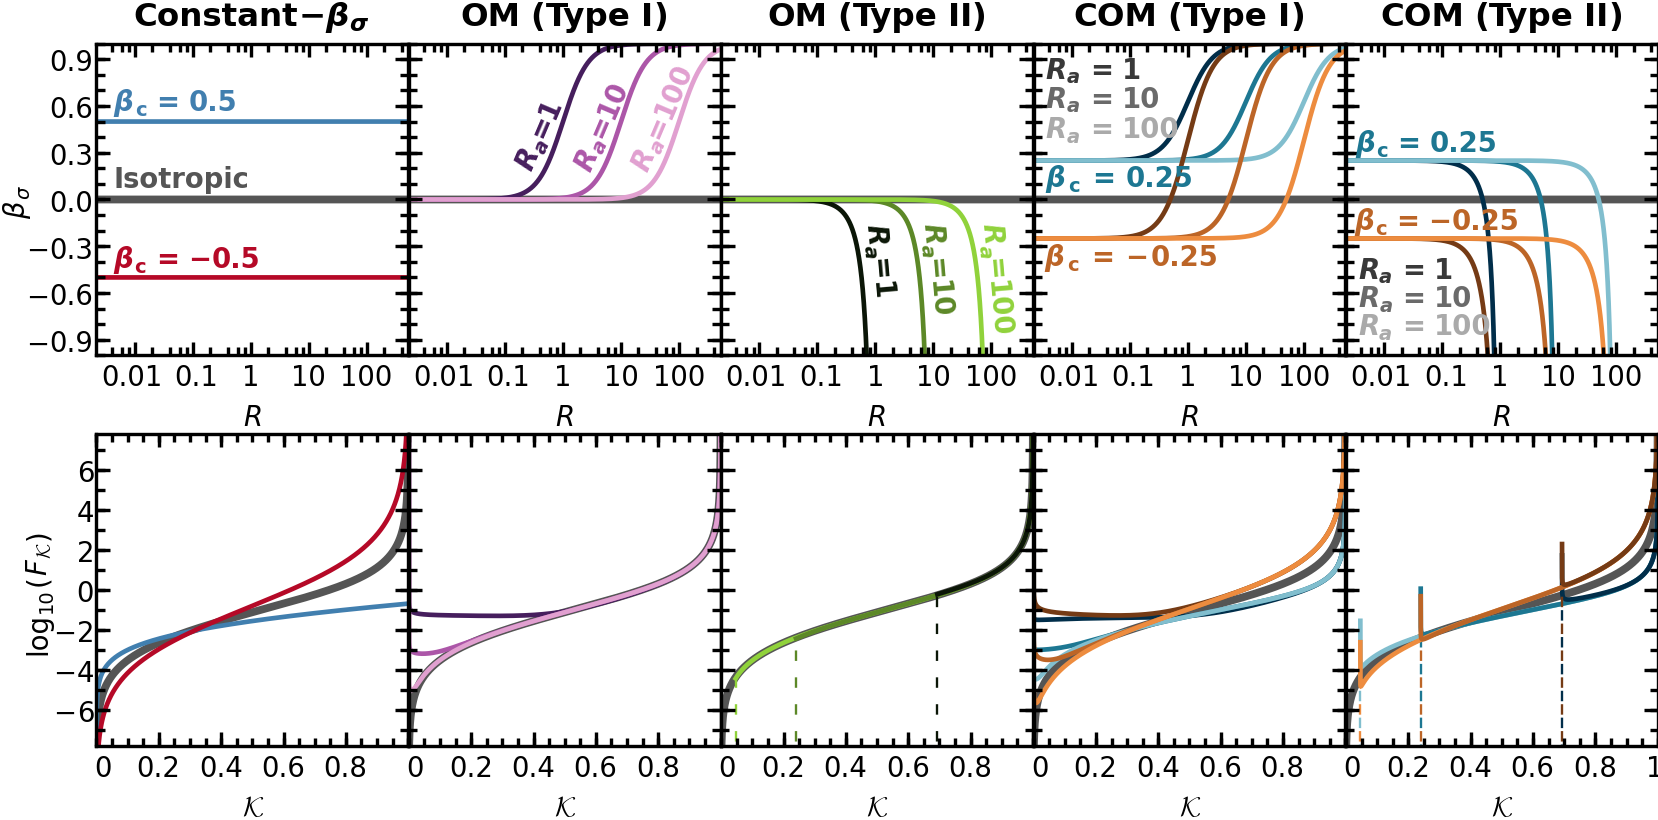

Saved -> DF_Untruncation_DFs.pdf (1194 x 591 pt)


In [9]:
W, H = 1194.0, 591.0
s = printed_scale(W)
page = mp.Page(W, H, [69.45 + 224.91 * i for i in range(5)], [32.0, 313.0])
R = np.geomspace(0.22e-2, 5.2e2, 20001)
R2 = lambda ra: np.unique(np.r_[R, ra * (1.0 - np.geomspace(1e-9, 1e-1, 4000))])  # noqa: E731  dense into R_a: the Type II plunge
PANELS4 = [  # (members, colors) of the five columns
    (["b+0.50", "b-0.50"], ["b05", "bm05"]),
    (["OMI_Ra1", "OMI_Ra10", "OMI_Ra100"], ["OM1", "OM10", "OM100"]),
    (["OMII_Ra1", "OMII_Ra10", "OMII_Ra100"], ["OMII1", "OMII10", "OMII100"]),
    ([f"COMI_b{b}_Ra{ra}" for b in ("+0.25", "-0.25") for ra in (1, 10, 100)],
     ["COMRa1U", "COMRa10U", "COMRa100U", "COMRa1", "COMRa10", "COMRa100"]),
    ([f"COMII_b{b}_Ra{ra}" for b in ("+0.25", "-0.25") for ra in (1, 10, 100)],
     ["COMRa1U", "COMRa10U", "COMRa100U", "COMRa1", "COMRa10", "COMRa100"])]


def beta_frame(col):
    ax = page.frame(col, 0, "log", (0.22e-2, 5.2e2), "linear", (-1.0, 1.0))
    tick(ax, "left", mp.arange(-2, 2, 0.1), 0.02, s); tick(ax, "left", mp.arange(-1.2, 0.9, 0.3), 0.04, s)
    tick(ax, "right", mp.arange(-2.1, 2, 0.1), 0.02, s); tick(ax, "right", mp.arange(-2.1, 2, 0.3), 0.04, s)
    mn = [x * 10.0 ** k for k in range(-3, 3) for x in (2, 4, 6, 8)]
    tick(ax, "bottom", mn, 0.02, s); tick(ax, "bottom", [10.0 ** k for k in range(-3, 4)], 0.04, s)
    tick(ax, "top", mn, 0.02, s); tick(ax, "top", [10.0 ** k for k in range(-4, 6)], 0.04, s)
    return ax


def type_I_end(tag, k, f):
    """the published list rules at the left end: OM Type I continued to the axis by the point {1e-10, 1e10}; COM Type I with
    beta_c > 0 closed to zero (LeftZeroPoint), with beta_c < 0 opened to the top (LeftInfPoint)"""
    kind, ra, bc = FAMILY[tag]
    if kind == "OMI":
        return np.r_[1e-10, k], np.r_[1e10, f]
    if kind == "COMI":
        p = f > 0
        return np.r_[0.99999 * k[p][0], k[p]], np.r_[1e-12 if bc > 0 else 1e12, f[p]]
    return k, f


def support(tag, k, f):
    """a Type II DF over its support only, K > P(R_a) = ln(1 + R_a) / R_a (the potential at the domain edge R_a)"""
    ra = FAMILY[tag][1]
    p_edge = math.log1p(ra) / ra
    inside = k > p_edge
    print(f"Fig. 4 {tag}: {inside.sum()} of {k.size} rows over the support K > P(R_a) = {p_edge:.10f}; "
          f"there F <= 0 on {int(np.sum(f[inside] <= 0))} rows, min F {f[inside].min():.3e}")
    return k[inside], f[inside]


# top row: beta_sigma(R)
for col, (tags, cols) in enumerate(PANELS4):
    ax = beta_frame(col)
    mp.curve(ax, R, 0 * R, C["iso"], 0.025)
    for tag, c in zip(tags, cols):
        r = R2(FAMILY[tag][1]) if FAMILY[tag][0].endswith("II") else R
        mp.curve(ax, r, beta_closed(tag, r), C[c], 0.015)

# bottom row: F(K); the Type II curves drawn R_a 100 first, R_a 1 last, each with the dashed vertical at its support edge
k_iso, f_iso = df_table(dfs["iso"])
for col, (tags, cols) in enumerate(PANELS4):
    ax = logF_frame(page, col, 1, s)
    mp.curve(ax, k_iso, f_iso, C["iso"], 0.025)
    pairs = list(zip(tags, cols))
    if col in (2, 4):
        pairs = [p for b in (pairs[:3], pairs[3:]) for p in b[::-1]]
    for tag, c in pairs:
        if dfs[tag] is None:
            continue
        k, f = df_table(dfs[tag])
        if FAMILY[tag][0].endswith("II"):
            k, f = support(tag, k, f)
            mp.curve(ax, k, f, C[c], 0.015)
            # half the width, AbsoluteDashing {6.5, 15}; the COM II +0.25 dashes offset by half a period, so that the two
            # colors sharing one P(R_a) alternate on one line
            off = 0.5 * (5.85 + 13.5) if FAMILY[tag][2] > 0 else 0.0
            ax.plot([k[0], k[0]], [1e-12, f[0]], color=C[c], lw=0.0075 * FRAME, ls=(off, (5.85, 13.5)),
                    dash_capstyle="projecting", clip_on=True)
        else:
            mp.curve(ax, *type_I_end(tag, k, f), C[c], 0.015)


def adjust4(sp):
    """the published placement edits on top of the export, in pt: the two beta_c labels of the top COM Type I panel 1.6 pt
    right; the R_a block of the top COM Type II panel 1.6 pt up"""
    x0, y0 = sp["origin"]
    if 744 < x0 < 969 and y0 < 257 and sp["color"] in ("#1d7792", "#bc6527"):
        return shifted(sp, 1.6, 0.0)
    if x0 > 969 and 180 < y0 < 257 and sp["color"] in ("#393939", "#6a6a6a", "#aaaaaa"):
        return shifted(sp, 0.0, -1.6)
    return sp


mp.draw_text(page, os.path.join(DATA, "layout_fig04.json"), adjust=adjust4)
page.save("DF_Untruncation_DFs.pdf")
import io

from IPython.display import Image, display
_png = io.BytesIO()  # the page inline as well: mma_port draws on the Agg backend, which displays nothing by itself
page.fig.savefig(_png, format="png")
display(Image(_png.getvalue()))
print(f"Saved -> DF_Untruncation_DFs.pdf ({W:g} x {H:g} pt)")

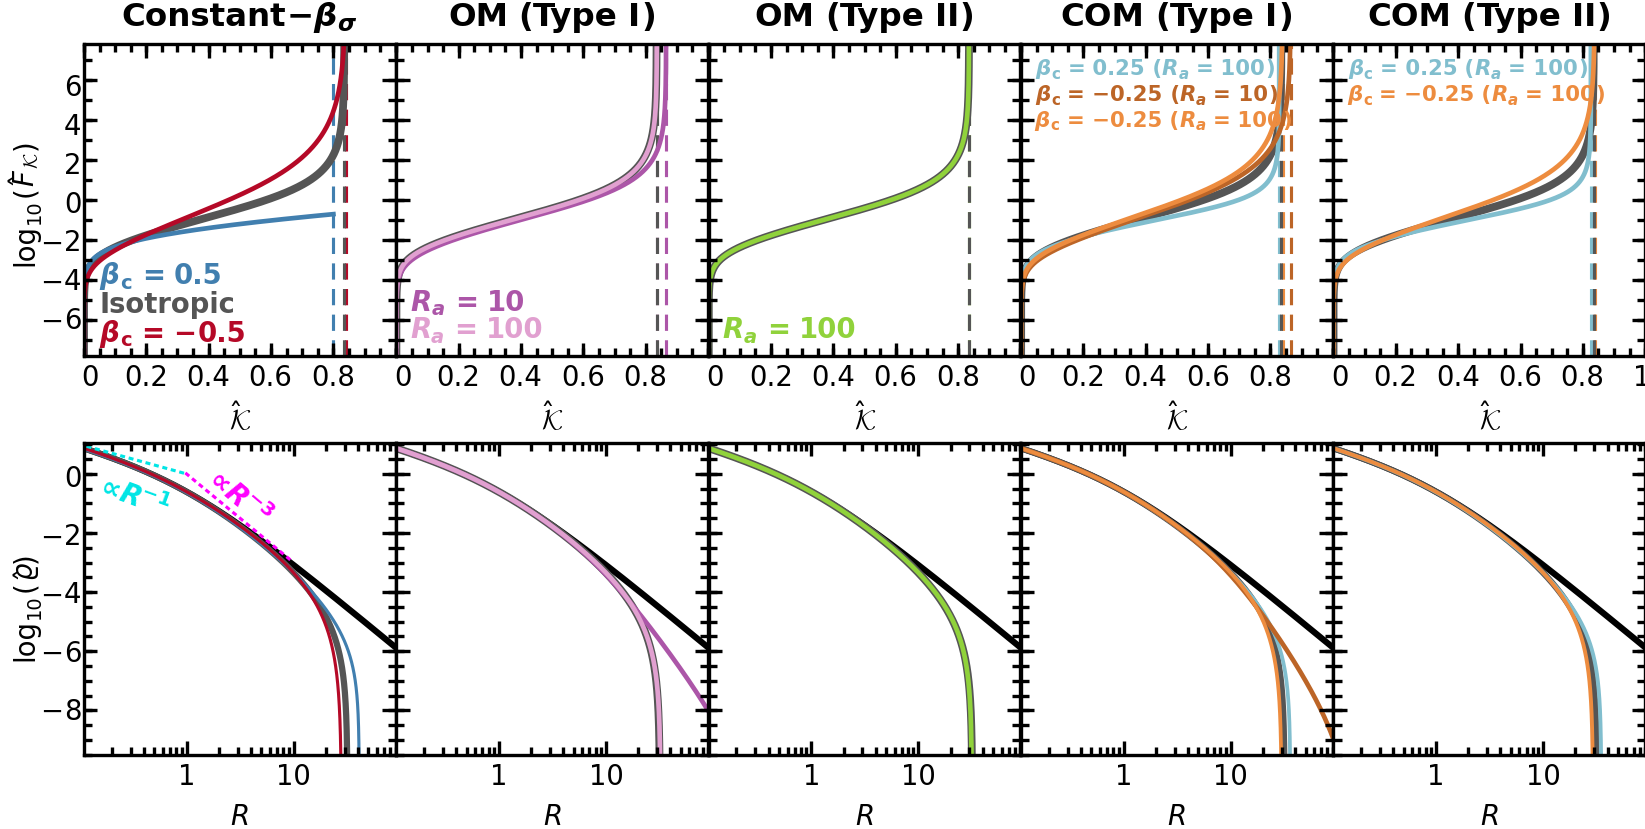

Saved -> DF_Truncation_DFs_I.pdf (1185 x 597 pt)


In [10]:
W, H = 1185.0, 597.0
s = printed_scale(W)
page = mp.Page(W, H, [60.45 + 224.91 * i for i in range(5)], [32.0, 319.0])


def fhat(tag):          # the point {0, 1e-12} prepended, as the published figure
    k, f = df_table(m1[tag])
    return np.r_[0.0, k], np.r_[1e-12, f]


def rho(tag):           # the point {1.0001 R_t, 1e-20} appended, as the published figure
    r, d = np.asarray(m1[tag].profile.r), np.asarray(m1[tag].profile.rho_trunc[0])
    return np.r_[r, 1.0001 * r[-1]], np.r_[d, 1e-20]


def rho_frame(col):
    ax = page.frame(col, 1, "log", (0.11, 0.9e2), "log", (10 ** -9.5, 10 ** 1.05))
    dec = [10.0 ** x for x in mp.arange(-20, 10, 0.5)]
    tick(ax, "left", dec, 0.02, s); tick(ax, "left", [10.0 ** x for x in range(-12, 9, 2)], 0.04, s)
    tick(ax, "right", dec, 0.02, s); tick(ax, "right", [10.0 ** x for x in range(-20, 11, 2)], 0.04, s)
    mn = [x * 10.0 ** k for k in range(-3, 3) for x in range(2, 10)]
    tick(ax, "bottom", mn, 0.02, s); tick(ax, "bottom", [10.0 ** k for k in range(-3, 3)], 0.04, s)
    tick(ax, "top", mn, 0.02, s); tick(ax, "top", [10.0 ** k for k in range(-4, 6)], 0.04, s)
    return ax


RN = 10.0 ** np.arange(-5.0, 3.5 + 1e-9, 0.0025)


def panel5(col, top_list, grid_list, bot_list, iso_bot):
    """top: gridlines at each curve's K^ end, then F^(K^); bottom: the untruncated NFW, the isotropic and the members' rho^(R)"""
    ax = logF_frame(page, col, 0, s)
    for tag, c in grid_list:
        if m1[tag] is not None:
            mp.gridline(ax, float(np.asarray(m1[tag].table.k[0])[-1]), C[c])
    for tag, c, th in top_list:
        if m1[tag] is not None:
            mp.curve(ax, *fhat(tag), C[c], th)
    ax = rho_frame(col)
    mp.curve(ax, RN, 1.0 / (RN * (1.0 + RN) ** 2), C["black"], 0.02)
    mp.curve(ax, *rho("iso"), C["iso"], iso_bot)
    for tag, c, th in bot_list:
        if m1[tag] is not None:
            mp.curve(ax, *rho(tag), C[c], th)
    return ax


ax = panel5(0, [("iso", "iso", 0.025), ("b+0.50", "b05", 0.015), ("b-0.50", "bm05", 0.015)],
            [("b+0.50", "b05"), ("b-0.50", "bm05"), ("iso", "iso")],
            [("b+0.50", "b05", 0.01), ("b-0.50", "bm05", 0.01)], 0.02)
r1, r3 = np.geomspace(0.1, 1.0, 200), np.geomspace(1.0, 10.0, 200)
mp.curve(ax, r1, 1.0 / r1, C["cyanguide"], 0.01, dash=(1.35, 4.95))          # the R^-1 and R^-3 guides
mp.curve(ax, r3, 1.0 / r3 ** 3, C["magenta"], 0.01, dash=(1.35, 4.95))
panel5(1, [("iso", "iso", 0.025), ("OMI_Ra10", "OM10", 0.015), ("OMI_Ra100", "OM100", 0.015)],
       [("OMI_Ra10", "OM10"), ("OMI_Ra100", "OM100"), ("iso", "iso")],
       [("OMI_Ra10", "OM10", 0.015), ("OMI_Ra100", "OM100", 0.015)], 0.025)
panel5(2, [("iso", "iso", 0.025), ("OMII_Ra10", "OMII10", 0.015), ("OMII_Ra100", "OMII100", 0.015)],
       [("OMII_Ra10", "OMII10"), ("OMII_Ra100", "OMII100"), ("iso", "iso")],
       [("OMII_Ra10", "OMII10", 0.015), ("OMII_Ra100", "OMII100", 0.015)], 0.025)
panel5(3, [("iso", "iso", 0.025), ("COMI_b+0.25_Ra100", "COMRa100U", 0.015), ("COMI_b-0.25_Ra10", "COMRa10", 0.015),
           ("COMI_b-0.25_Ra100", "COMRa100", 0.015)],
       [("COMI_b+0.25_Ra100", "COMRa100U"), ("COMI_b-0.25_Ra10", "COMRa10"), ("COMI_b-0.25_Ra100", "COMRa100"), ("iso", "iso")],
       [("COMI_b+0.25_Ra100", "COMRa100U", 0.012), ("COMI_b-0.25_Ra10", "COMRa10", 0.015), ("COMI_b-0.25_Ra100", "COMRa100", 0.012)],
       0.02)
panel5(4, [("iso", "iso", 0.025), ("COMII_b+0.25_Ra10", "COMRa10U", 0.015), ("COMII_b+0.25_Ra100", "COMRa100U", 0.015),
           ("COMII_b-0.25_Ra10", "COMRa10", 0.015), ("COMII_b-0.25_Ra100", "COMRa100", 0.015)],
       [("COMII_b+0.25_Ra10", "COMRa10U"), ("COMII_b+0.25_Ra100", "COMRa100U"), ("COMII_b-0.25_Ra10", "COMRa10"),
        ("COMII_b-0.25_Ra100", "COMRa100"), ("iso", "iso")],
       [("COMII_b+0.25_Ra10", "COMRa10U", 0.0125), ("COMII_b+0.25_Ra100", "COMRa100U", 0.0125),
        ("COMII_b-0.25_Ra10", "COMRa10", 0.0125), ("COMII_b-0.25_Ra100", "COMRa100", 0.0125)], 0.02)

# the published labels were laid out for the three members refused at these K_t (OM II R_a 10, COM II +0.25 and -0.25 R_a 10):
# their labels removed and the others of those panels restacked into the freed rows
PUBLISHED_REFUSED = {"OMII_Ra10", "COMII_b+0.25_Ra10", "COMII_b-0.25_Ra10"}
refused5 = {tag for tag, m in m1.items() if m is None}
if refused5 != PUBLISHED_REFUSED:
    print(f"note: refused here {sorted(refused5)}, the published labels assume {sorted(PUBLISHED_REFUSED)}")


def adjust5(sp):
    x, y = sp["origin"]
    top_row = y < 257
    if top_row and 510 < x < 735 and sp["color"] == "#5c8827":
        return None
    if top_row and x > 960 and sp["color"] in ("#1d7792", "#bc6527"):
        return None
    if top_row and x > 960:
        return shifted(sp, 0.0, {"#81bece": -18.7, "#ed8c3f": -37.2}.get(sp["color"], 0.0))
    return sp


mp.draw_text(page, os.path.join(DATA, "layout_fig05.json"), adjust=adjust5)
page.save("DF_Truncation_DFs_I.pdf")
_png = io.BytesIO()  # the page inline as well: mma_port draws on the Agg backend, which displays nothing by itself
page.fig.savefig(_png, format="png")
display(Image(_png.getvalue()))
print(f"Saved -> DF_Truncation_DFs_I.pdf ({W:g} x {H:g} pt)")

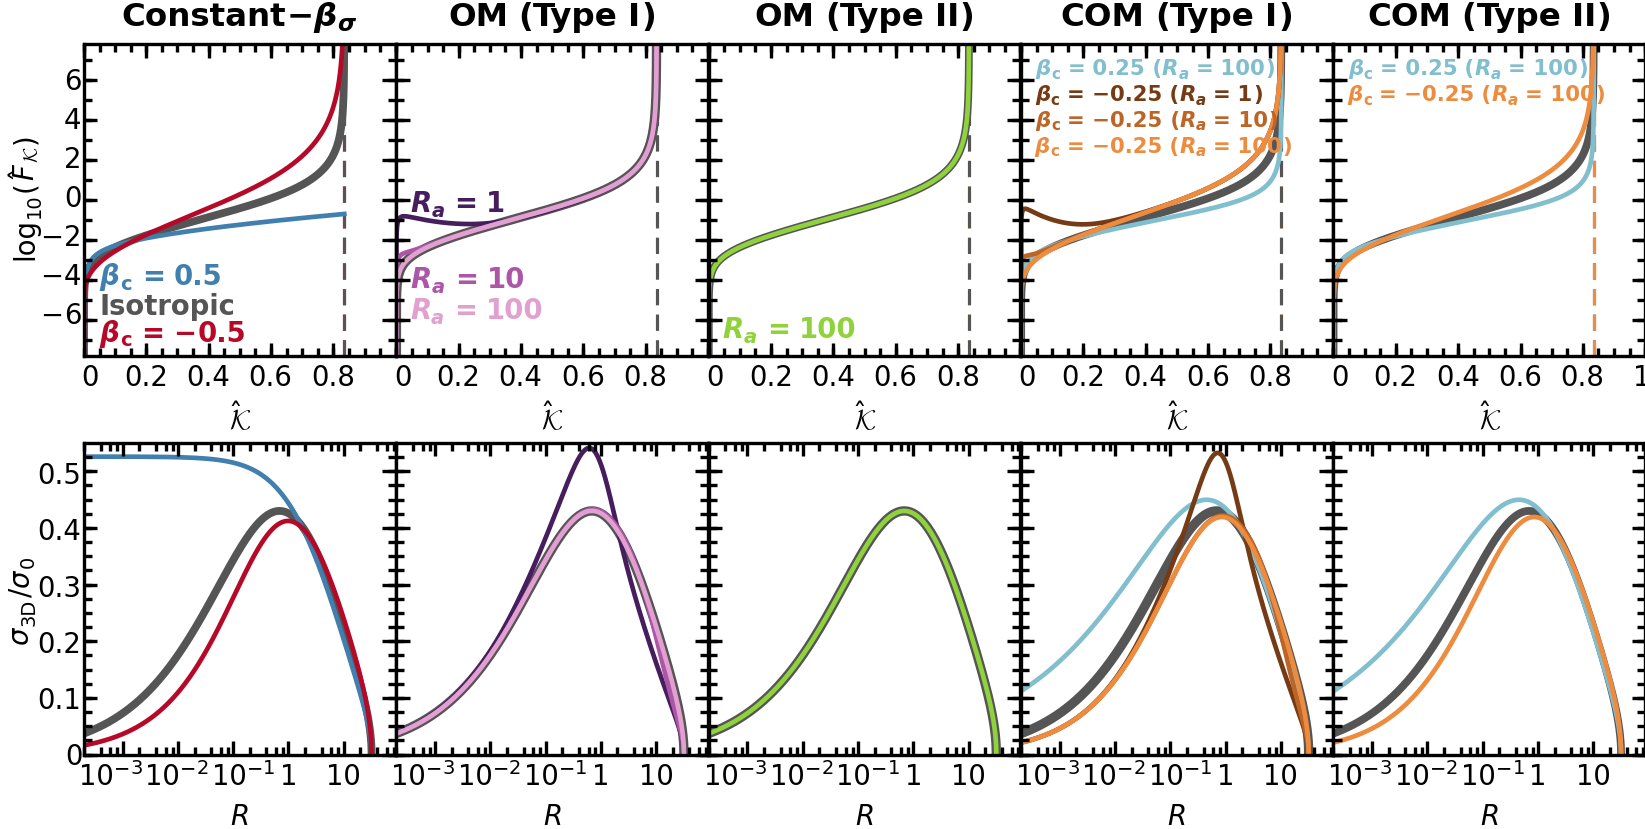

Saved -> DF_Truncation_DFs_II.pdf (1185 x 597 pt)


In [11]:
W, H = 1185.0, 597.0
s = printed_scale(W)
page = mp.Page(W, H, [60.45 + 224.91 * i for i in range(5)], [32.0, 319.0])


def sigma_frame(col):
    ax = page.frame(col, 1, "log", (0.0002, 0.87e2), "linear", (0.0, 0.55))
    tick(ax, "left", mp.arange(-10, 30, 0.025), 0.02, s); tick(ax, "left", mp.arange(0, 0.5, 0.1), 0.04, s)
    tick(ax, "right", mp.arange(-10, 30, 0.025), 0.02, s); tick(ax, "right", mp.arange(-10, 30, 0.1), 0.04, s)
    mn = [x * 10.0 ** k for k in range(-4, 3) for x in (2, 4, 6, 8)]
    tick(ax, "bottom", mn, 0.02, s); tick(ax, "bottom", [10.0 ** k for k in range(-3, 4)], 0.04, s)
    tick(ax, "top", mn, 0.02, s); tick(ax, "top", [10.0 ** k for k in range(-4, 6)], 0.04, s)
    return ax


K_END = float(np.asarray(truncated.table.k[0])[-1])


def panel6(col, members, grid_cols, iso_top, iso_bot):
    """top: gridlines at the isotropic K^ end, the Method I model's F^ and the members'; bottom: sigma_3D / sigma_0"""
    ax = logF_frame(page, col, 0, s)
    for c in grid_cols:
        mp.gridline(ax, K_END, C[c])
    mp.curve(ax, *df_table(truncated), C["iso"], iso_top)
    for tag, c in members:
        if m2[tag] is not None:
            mp.curve(ax, *df_table(m2[tag]), C[c], 0.015)
    ax = sigma_frame(col)
    mp.curve(ax, *S3["iso"], C["iso"], iso_bot)
    for tag, c in members:
        if tag in S3:
            mp.curve(ax, *S3[tag], C[c], 0.015)


panel6(0, [("b+0.50", "b05"), ("b-0.50", "bm05")], ["bm05", "iso"], 0.025, 0.025)
panel6(1, [("OMI_Ra1", "OM1"), ("OMI_Ra10", "OM10"), ("OMI_Ra100", "OM100")], ["OM100", "iso"], 0.03, 0.03)
panel6(2, [("OMII_Ra100", "OMII100")], ["OMII100", "iso"], 0.025, 0.03)
panel6(3, [("COMI_b+0.25_Ra100", "COMRa100U"), ("COMI_b-0.25_Ra1", "COMRa1"), ("COMI_b-0.25_Ra10", "COMRa10"),
           ("COMI_b-0.25_Ra100", "COMRa100")], ["COMRa100", "iso"], 0.025, 0.03)
panel6(4, [("COMII_b+0.25_Ra100", "COMRa100U"), ("COMII_b-0.25_Ra100", "COMRa100")], ["iso", "COMRa100"], 0.025, 0.025)
mp.draw_text(page, os.path.join(DATA, "layout_fig06.json"))
page.save("DF_Truncation_DFs_II.pdf")
_png = io.BytesIO()  # the page inline as well: mma_port draws on the Agg backend, which displays nothing by itself
page.fig.savefig(_png, format="png")
display(Image(_png.getvalue()))
print(f"Saved -> DF_Truncation_DFs_II.pdf ({W:g} x {H:g} pt)")

## Against the published files

The three PDFs written here were compared with the paper's files, page by page: the text spans (string, origin, size), the frame and tick strokes (width and length), and every curve, read back from the PDF paths into data units (matplotlib simplifies a path to about 0.1 pt, 0.007 dex on the log F axes, so smaller differences are not resolved).

**Style.** The pages (1194 x 591 pt and 1185 x 597 pt), the frames, the colors, the curve widths and the curve rules are the paper's. The frame and tick strokes are the same in number, width and length in all three figures: 1.02 pt lines, ticks 4.08 and 2.45 pt as printed at 0.99 of the text width. The text differs in one respect: it is set in DejaVu Sans here, where the paper's files use Liberation Sans and draw the script K, the hat, varrho and some signs from the outlines of the fonts embedded in the original Mathematica exports, which are not free to redistribute. Each label is laid out again at the DejaVu Sans widths from the export's position (`scripts/dejavu_labels.py`), so the label positions move by 2 pt (median), at most 14 pt (Fig. 4) and 24 pt (Figs. 5 and 6), all sizes unchanged. The wider font makes two places tighter than in the paper: the long labels of the top COM panels of Fig. 5 reach the right frame, and the decade labels $10^{-1}$ and 1 of the bottom row of Fig. 6 nearly touch.

**Data.** The paper's curves were drawn from stored products of the same models; here every curve comes from the package's public calls.

* Fig. 4, top row: the same closed forms. Bottom row: the Type II curves (all nine) start at the same energies, $P(R_{\rm a}) = \ln(1 + R_{\rm a})/R_{\rm a}$ (the first table row above 0.6931, 0.2398 and 0.0462 for $R_{\rm a}$ = 1, 10, 100), and agree with the paper's to the precision of the PDF paths, with the same dashed vertical at each support edge and no other jump. The other curves agree to $8\times10^{-4}$ dex or better (median) and at most $1.4\times10^{-2}$ dex for $\mathcal{K} < 0.995$ (COM I $\beta_{\rm c} = -0.25$, $R_{\rm a} = 10$); the largest differences, up to 0.028 dex, are at $\mathcal{K} > 0.995$, where $F$ rises steeply and the two tables sample the curve at different points.
* Fig. 5, top row: identical to the precision of the PDF paths. Bottom row: the densities agree to $10^{-4}$ dex (median); the largest difference, $7.7\times10^{-3}$ dex, is at $R = 40$, just inside the truncation radius of $\beta_{\rm c} = +0.5$; the others are below $2.6\times10^{-3}$ dex. The same three members are refused as in the paper (OM II $R_{\rm a} = 10$, COM II $\beta_{\rm c} = \pm0.25$ $R_{\rm a} = 10$), so their labels are left out as there.
* Fig. 6, top row: identical to $5\times10^{-5}$ dex. Bottom row: $\sigma_{\rm 3D}/\sigma_0$ from `pp.sigma_r` and `pp.sigma_t` against the paper's Jeans solution on the stored profiles: $10^{-4}$ (median), at most $4.4\times10^{-3}$, at $R \approx 31.8$, just inside the truncation radius.
